# Solar filament instance segmentation — full pipeline

IEEE BigData Cup 2026, Challenge 02 (MAGFiLO H-alpha full-disk images, Panoptic Quality).

This notebook runs the whole method end to end:

1. **Preprocessing** — solar disk detection, radial limb-darkening flattening, CLAHE.
2. **Targets** — mean over annotator records (soft target) plus filament spines as an auxiliary target.
3. **Model** — ConvNeXt-tiny U-Net (encoder-output LayerNorm, ASPP, local scSE, full/half-resolution stems), trained on
   1024 px crops of the native 2048 px images, 4 station-stratified folds.
4. **Inference** — full 2048 px input, 4 flips; test images use the mean of the 4 fold models.
5. **Post-processing** — hysteresis components, 31 features per component, a gradient-boosted *PQ-aware scorer* that
   predicts each component's expected matched IoU, and a keep threshold tuned out of fold.
6. **Evaluation** — out-of-fold PQ with the organisers' own evaluation functions, IoU / Dice / one-to-many statistics.
7. **Submission** for the test set.

`TRAIN = False` (default) reproduces every result from the weights in `weights/` (GPU recommended, ~1.5 h; CPU works
but is slow). `TRAIN = True` retrains everything from scratch (about 4.7 h of training on one NVIDIA A100, longer on smaller GPUs) and can be resumed
after an interruption by running the notebook again.

In [1]:
# ---------------------------------------------------------------------------------------------------- settings
import os, sys, json, time, glob, pickle, platform
from pathlib import Path

TRAIN = globals().get("TRAIN", False)                 # True: retrain from scratch; False: use the shipped weights
REPO_DIR = Path(globals().get("REPO_DIR", ".."))      # repository root (configs/, splits/, weights/, filament/)
DATA_DIR = Path(globals().get("DATA_DIR", os.environ.get("DATA_DIR", "/kaggle/input")))   # competition data
WORK_DIR = Path(globals().get("WORK_DIR", os.environ.get("WORK_DIR", "./work")))          # outputs, checkpoints, logs
CACHE_DIR = Path(globals().get("CACHE_DIR", WORK_DIR / "cache"))      # preprocessing cache (fast local disk preferred)
OOF_DIR = Path(globals().get("OOF_DIR", WORK_DIR / "oof"))            # out-of-fold probabilities (~3 GB)
TIME_BUDGET_H = globals().get("TIME_BUDGET_H", None)  # stop training before this many hours (session limits)
WORKERS = int(globals().get("WORKERS", max(1, min(8, (os.cpu_count() or 2)))))
DRY = os.environ.get("DRY") == "1"                    # tiny smoke test (synthetic data, 256 px, 2 epochs)

sys.path.insert(0, str(REPO_DIR))
import numpy as np, pandas as pd, cv2, torch, sklearn
import matplotlib.pyplot as plt
from filament.config import load_config, scaled
from filament.data import Annotations, make_folds, build_cache, find_files, IMAGE_EXT
from filament.model import load_model, export_half
from filament.train import train_model
from filament import pipeline as pl, evaluate as ev, postprocess as pp, official_eval as oe
from filament.submission import check_submission

cfg = load_config(REPO_DIR / "configs" / "final.yaml")
if DRY:
    cfg = scaled(cfg, 256)
    cfg["train"].update(epochs=2, val_every=1, workers=0)
WORK_DIR.mkdir(parents=True, exist_ok=True)
log = pl.log_to(WORK_DIR / "pipeline.log")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = cfg["seed"]
from importlib.metadata import version as _version, PackageNotFoundError
def _pkg(*names):
    for n in names:
        try:
            return _version(n)
        except PackageNotFoundError:
            pass
    return "missing"
VERSIONS = dict(python=platform.python_version(), gpu=torch.cuda.get_device_name(0) if device.type == "cuda" else "none",
                torch=_pkg("torch"), timm=_pkg("timm"), numpy=_pkg("numpy"), scipy=_pkg("scipy"), pandas=_pkg("pandas"),
                scikit_learn=_pkg("scikit-learn"), scikit_image=_pkg("scikit-image"),
                opencv=_pkg("opencv-python", "opencv-python-headless", "opencv-contrib-python"),
                pycocotools=_pkg("pycocotools"), pyyaml=_pkg("PyYAML"), matplotlib=_pkg("matplotlib"))
log(f"TRAIN={TRAIN} | device {device} | {VERSIONS}")

TRAIN=False | device cuda | {'python': '3.13.16', 'gpu': 'NVIDIA L4', 'torch': '2.11.0', 'timm': '1.0.30', 'numpy': '2.1.3', 'scipy': '1.16.3', 'pandas': '2.2.3', 'scikit_learn': '1.6.1', 'scikit_image': '0.25.2', 'opencv': '5.0.0.93', 'pycocotools': '2.0.11', 'pyyaml': '6.0.3', 'matplotlib': '3.10.0'}


In [2]:
# -------------------------------------------------------------------------------------- annotations and folds
ann_path = find_files(DATA_DIR, "*kaggle2026_train.json")[0]
train_dir = [d for d in find_files(DATA_DIR, "train_images") if os.path.isdir(d)][0]
test_dir = [d for d in find_files(DATA_DIR, "test_images") if os.path.isdir(d)][0]
ann = Annotations(ann_path, train_dir)
folds_path = REPO_DIR / "splits" / "folds.csv"
generated = make_folds(ann.meta, cfg["data"]["n_folds"], SEED)
if folds_path.exists():
    folds = pd.read_csv(folds_path)
    same = folds.merge(generated, on="stem", suffixes=("", "_gen")).eval("fold == fold_gen").all()
    log(f"folds: {folds_path} (identical to make_folds(seed={SEED}): {same})")
else:
    folds = generated
    folds_path.parent.mkdir(parents=True, exist_ok=True)
    folds.to_csv(folds_path, index=False)
    log(f"folds generated -> {folds_path}")
folds = folds[folds.stem.isin(ann.meta.stem)].reset_index(drop=True)
STEMS = folds.stem.tolist()
FOLD_OF = dict(zip(folds.stem, folds.fold))
N_FOLDS = int(folds.fold.nunique())
test_files = sorted(p for p in glob.glob(f"{test_dir}/*") if Path(p).suffix.lower() in IMAGE_EXT)
log(f"{len(STEMS)} training images ({ann.meta.K.gt(1).sum()} with several annotator records), "
    f"{len(test_files)} test images | fold sizes {folds.fold.value_counts().sort_index().tolist()}")

folds: ../splits/folds.csv (identical to make_folds(seed=42): True)


707 training images (296 with several annotator records), 180 test images | fold sizes [180, 178, 175, 174]


cache /content/verify/cache: 0 ready, 707 to build


  100/707 (30s)


  200/707 (57s)


  300/707 (85s)


  400/707 (112s)


  500/707 (139s)


  600/707 (162s)


  700/707 (186s)


cache built in 187s


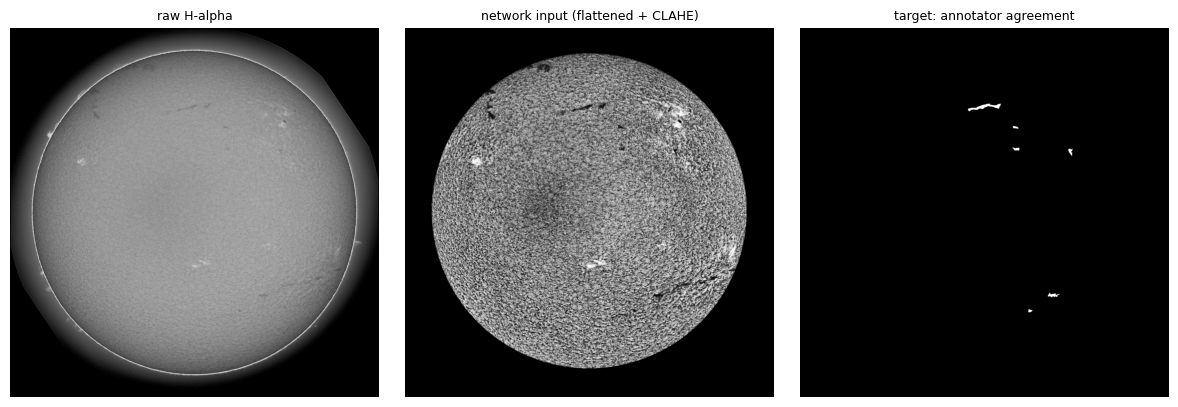

In [3]:
# ------------------------------------------------------------------------------------------ preprocessing cache
build_cache(ann, STEMS, CACHE_DIR, cfg, workers=WORKERS, log=log)
x0 = cv2.imread(str(CACHE_DIR / "x" / f"{STEMS[0]}.png"), cv2.IMREAD_GRAYSCALE)
raw0 = cv2.imread(ann.meta.set_index("stem").at[STEMS[0], "path"], cv2.IMREAD_GRAYSCALE)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, t in zip(ax, (raw0, x0, cv2.imread(str(CACHE_DIR / "y" / f"{STEMS[0]}.png"), 0)),
                    ("raw H-alpha", "network input (flattened + CLAHE)", "target: annotator agreement")):
    a.imshow(im, cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(WORK_DIR / "preprocessing_example.png", dpi=110); plt.show()

## Training (only with `TRAIN = True`)
One model per fold. Every epoch writes a resumable state; with `TIME_BUDGET_H` set the loop stops cleanly before the
budget and the next run continues where it stopped. The best checkpoint (validation IoU, full resolution) is kept and
exported in half precision to `weights/` (< 100 MB per file).

In [4]:
WEIGHTS_DIR = (WORK_DIR / "weights") if TRAIN else (REPO_DIR / "weights")
if TRAIN:
    deadline = time.time() + TIME_BUDGET_H * 3600 if TIME_BUDGET_H else None
    status, histories = {}, []
    for f in range(N_FOLDS):
        r = train_model(cfg, f"convnext_fold{f}", folds.stem[folds.fold != f].tolist(), folds.stem[folds.fold == f].tolist(),
                        CACHE_DIR, WORK_DIR, device, seed=SEED + f, pretrained=not DRY, deadline=deadline, log=log)
        status[f] = r["status"]
        histories += [dict(fold=f, **h) for h in r["history"]]
        if r["status"] != "done":
            break
    pd.DataFrame(histories).to_csv(WORK_DIR / "training_history.csv", index=False)
    if not all(status.get(f) == "done" for f in range(N_FOLDS)):
        raise SystemExit("Training paused (time budget). Run the notebook again to continue.")
    WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
    for f in range(N_FOLDS):
        export_half(WORK_DIR / "ckpt" / f"convnext_fold{f}.pt", WEIGHTS_DIR / f"convnext_fold{f}.pt")
    # half-precision export must not change predictions: compare on a few validation images of fold 0
    va0 = folds.stem[folds.fold == 0].tolist()[:4]
    n32, n16 = load_model(WORK_DIR / "ckpt" / "convnext_fold0.pt", cfg, device), load_model(WEIGHTS_DIR / "convnext_fold0.pt", cfg, device)
    from filament.infer import predict
    from filament.data import read_cache
    d = max(float(np.abs(predict([n32], read_cache(CACHE_DIR, "x", s), device) - predict([n16], read_cache(CACHE_DIR, "x", s), device)).max())
            for s in va0)
    log(f"fp16 export: max |delta probability| on {len(va0)} validation images = {d:.4f}")
    del n32, n16
    h = pd.DataFrame(histories).dropna(subset=["val_iou"])
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for f, g in h.groupby("fold"):
        ax.plot(g.epoch, g.val_iou, marker="o", ms=3, label=f"fold {f}")
    ax.set_xlabel("epoch"); ax.set_ylabel("validation IoU"); ax.legend(frameon=False); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(WORK_DIR / "training_curves.png", dpi=120); plt.show()
CKPTS = {f: WEIGHTS_DIR / f"convnext_fold{f}.pt" for f in range(N_FOLDS)}
assert all(p.exists() for p in CKPTS.values()), f"missing weights in {WEIGHTS_DIR}"
log(f"weights: {WEIGHTS_DIR}")

weights: ../weights


## Out-of-fold predictions and the component scorer
Every training image is predicted by the fold model that never saw it. Components are scored by a gradient-boosted
regressor of their expected matched IoU *u*; the regressor is cross-fitted with the same folds, so every reported
number is out of fold. A component pays off when *u* > PQ/2; the threshold τ is tuned on the pooled OOF predictions.

OOF fold 0: done (2.9 min)


OOF fold 1: done (5.7 min)


OOF fold 2: done (8.5 min)


OOF fold 3: done (11.2 min)


  candidates 100/707 (0.9 min)


  candidates 200/707 (1.8 min)


... (5 outputs left out)

candidates: 6446 components in 707 images (5.9 min)


                      PQ        SQ        RQ      TP      FP      FN
all components  0.409172  0.674820  0.606343  5659.0  4808.0  2540.0
with scorer     0.443195  0.679874  0.651878  4981.0  2102.0  3218.0


scorer vs keeping every component: +0.0340 [+0.0290, +0.0390] | tau = 0.2625


OOF PQ per fold: 0.4415 / 0.4468 / 0.4404 / 0.4437


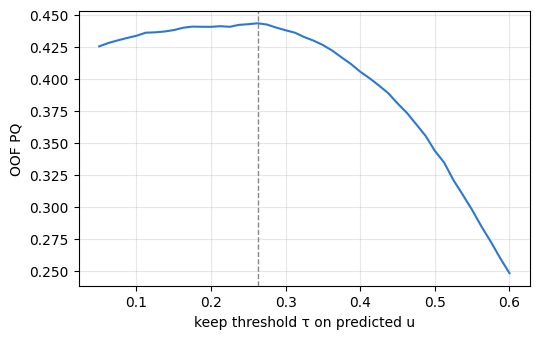

In [5]:
prob_path = pl.oof_probabilities(cfg, STEMS, FOLD_OF, CKPTS, CACHE_DIR, OOF_DIR, device, log=log)
C = pl.candidates(prob_path, STEMS, ann, CACHE_DIR, cfg, workers=WORKERS, log=log)
R = pl.evaluate_scorer(C, STEMS, FOLD_OF, cfg, SEED, station=cfg["scorer"]["station_feature"])
TAU = R["tau"]
res = {"all components": ev.summary(R["P_all"]), "with scorer": ev.summary(R["P"])}
log(pd.DataFrame(res).T.to_string())
bs = ev.paired_bootstrap(R["P"], R["P_all"])
log(f"scorer vs keeping every component: {bs['diff']:+.4f} [{bs['lo']:+.4f}, {bs['hi']:+.4f}] | tau = {TAU:.4f}")
fold_pq = {f: ev.pq(R["P"][[FOLD_OF[s] == f for s in STEMS]]) for f in range(N_FOLDS)}
log("OOF PQ per fold: " + " / ".join(f"{v:.4f}" for v in fold_pq.values()))
with open(WORK_DIR / "oof_candidates.pkl", "wb") as fh:                     # for the CPU ablations in experiments/
    pickle.dump(dict(C=C, stems=STEMS, fold_of=FOLD_OF, U=R["U"], tau=TAU), fh)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
t_, p_ = zip(*R["curve"])
ax.plot(t_, p_, color="#2a78d6"); ax.axvline(TAU, color="#888", ls="--", lw=1)
ax.set_xlabel("keep threshold τ on predicted u"); ax.set_ylabel("OOF PQ"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(WORK_DIR / "tau_curve.png", dpi=120); plt.show()

In [6]:
# ------------------------------------------------------------------------------------- final scorer for the test set
scorer_path = WEIGHTS_DIR / "scorer.pkl"
if TRAIN:
    scorer = pl.fit_scorer(C, STEMS, cfg, SEED, station=cfg["scorer"]["station_feature"])
    with open(scorer_path, "wb") as fh:
        pickle.dump(dict(model=scorer, tau=TAU, features=pp.feature_names(cfg["scorer"]["station_feature"]),
                         sklearn=sklearn.__version__, postprocess=cfg["postprocess"]), fh)
else:
    with open(scorer_path, "rb") as fh:
        S = pickle.load(fh)
    scorer = S["model"]
    log(f"shipped scorer: tau={S['tau']:.4f} (recomputed here: {TAU:.4f}), trained with scikit-learn {S['sklearn']}")
    TAU = S["tau"]

shipped scorer: tau=0.2250 (recomputed here: 0.2625), trained with scikit-learn 1.6.1


## Official evaluation (organisers' functions, unchanged)

official PQ (OOF, 707 images) = 0.4432 | internal 0.4432


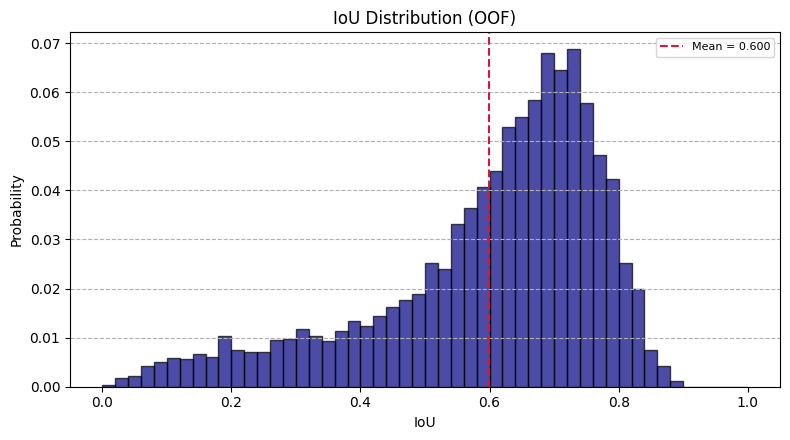

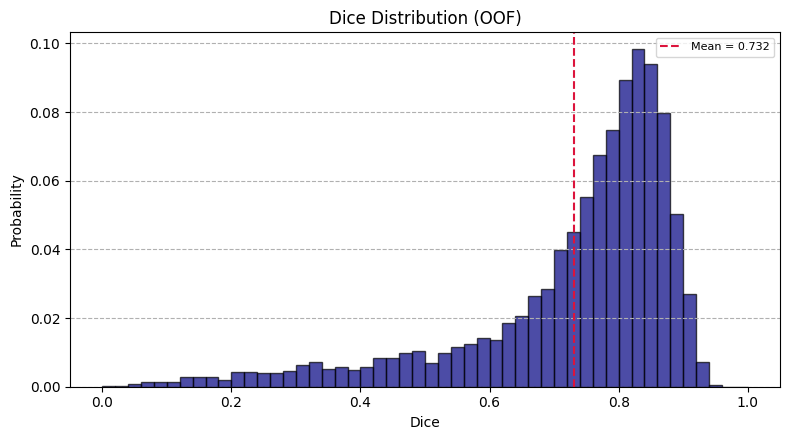

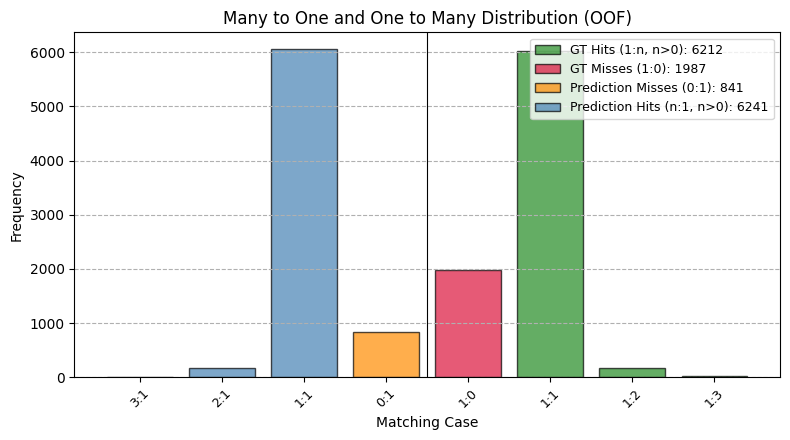

{"pairs": 6428, "iou_mean": 0.5997191016821918, "iou_median": 0.6469565629959106, "iou_above_05": 0.7748911014312383, "dice_mean": 0.7315534358640162, "dice_median": 0.7856388986110687, "gt_one_to_n": {"0": 1987, "1": 6018, "2": 172, "3": 22}, "pred_n_to_one": {"0": 841, "1": 6065, "2": 165, "3": 11}}


In [7]:
pred_df, gt_df = pl.oof_frames(prob_path, STEMS, ann, R["U"], R["tau"], cfg, workers=WORKERS)
pred_df.to_csv(WORK_DIR / "oof_pred.csv", index=False); gt_df.to_csv(WORK_DIR / "oof_gt.csv", index=False)
overlap_df = oe.get_overlap_df(gt_df, pred_df)
PQ_OFFICIAL = oe.get_pq_score(overlap_df)
log(f"official PQ (OOF, {len(STEMS)} images) = {PQ_OFFICIAL:.4f} | internal {ev.pq(R['P']):.4f}")
for name, fn, args in (("iou_distribution", oe.plot_distribution, (overlap_df["iou_matrix"], "IoU Distribution (OOF)", "IoU")),
                       ("dice_distribution", oe.plot_distribution, (overlap_df["dice_matrix"], "Dice Distribution (OOF)", "Dice")),
                       ("many_to_one", oe.plot_m2n_counts, (overlap_df, "Many to One and One to Many Distribution (OOF)"))):
    plt.figure(figsize=(8, 4.5)); fn(*args); plt.tight_layout(); plt.savefig(WORK_DIR / f"{name}.png", dpi=130); plt.show()
ious = np.concatenate([np.asarray(m, float).ravel() for m in overlap_df.iou_matrix]); ious = ious[ious > 0]
dices = np.concatenate([np.asarray(m, float).ravel() for m in overlap_df.dice_matrix]); dices = dices[dices > 0]
gt_deg, pr_deg = [], []
for r in overlap_df.itertuples(index=False):
    if r.n_gt == 0: pr_deg += [0] * r.n_pred; continue
    if r.n_pred == 0: gt_deg += [0] * r.n_gt; continue
    hit = r.iou_matrix > 0; gt_deg += hit.sum(1).tolist(); pr_deg += hit.sum(0).tolist()
STATS = dict(pairs=int(len(ious)), iou_mean=float(ious.mean()), iou_median=float(np.median(ious)),
             iou_above_05=float((ious > 0.5).mean()), dice_mean=float(dices.mean()), dice_median=float(np.median(dices)),
             gt_one_to_n={int(k): int(v) for k, v in sorted(pd.Series(gt_deg).value_counts().items())},
             pred_n_to_one={int(k): int(v) for k, v in sorted(pd.Series(pr_deg).value_counts().items())})
log(json.dumps(STATS))

## Test set: 4 fold models × 4 flips → components → scorer → submission

In [8]:
nets = [load_model(CKPTS[f], cfg, device) for f in range(N_FOLDS)]
sub, test_shapes = pl.predict_test(test_files, nets, scorer, TAU, cfg, device, log=log)
sub.to_csv(WORK_DIR / "submission.csv", index=False)
chk = check_submission(sub, test_shapes)
chk["sizes"] = sorted({f"{h}x{w}" for h, w in test_shapes.values()})
log(f"submission: {chk}")
del nets

  test 20/180 (2.3 min)


  test 40/180 (4.6 min)


  test 60/180 (6.9 min)


  test 80/180 (9.2 min)


  test 100/180 (11.5 min)


  test 120/180 (13.7 min)


  test 140/180 (16.0 min)


  test 160/180 (18.2 min)


  test 180/180 (20.5 min)


submission: {'rows': 1083, 'images': 180, 'missing_images': 0, 'per_image': 6.016666666666667, 'sizes': ['2048x2048']}


In [9]:
# ------------------------------------------------------------------------------------------------------- summary
results = dict(train=TRAIN, oof=dict(all_components=ev.summary(R["P_all"]), scorer=ev.summary(R["P"]), tau=R["tau"],
                                     per_fold=fold_pq, scorer_vs_all=bs, official_pq=PQ_OFFICIAL, overlap=STATS),
               test=chk, versions=VERSIONS, config=cfg)
(WORK_DIR / "results.json").write_text(json.dumps(results, indent=1, default=float))
log(f"done -> {WORK_DIR}")

done -> /content/verify
